# Smart Merchant: End-to-End Lab Machine Learning Pipeline
### College Data Mining & DWDM Laboratory Submission
**Project:** Smart Merchant Application — AI-Powered Merchant Management and Business Intelligence Platform  
**Algorithms Used:**
1. **Sales Prediction** — Linear Regression
2. **Product Demand** — K-Nearest Neighbors (KNN) Regression
3. **Catalog Classification** — Decision Tree Classifier
4. **Inventory Status** — Logistic Regression
5. **Expense Prediction** — Multiple Linear Regression
6. **Business Segmentation** — K-Means Clustering
7. **Profit Prediction** — Linear Regression

---
## Pipeline Overview
This notebook executes the complete machine learning lifecycle:
`Data Loading -> Preprocessing -> EDA -> Model Training & Tuning -> Evaluation -> Joblib Persistence -> Business Decision Synthesis`


## Section 1: Library Imports & Master Dataset Loading

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Scikit-Learn tools
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score, davies_bouldin_score
)

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# Load dataset
data_path = os.path.join("..", "data", "smart_merchant_master.csv")
if not os.path.exists(data_path):
    sys.path.append(os.path.abspath(".."))
    from data.generate_data import generate_master_dataset
    df = generate_master_dataset(num_records=1000, random_state=42, output_path=data_path)
else:
    df = pd.read_csv(data_path)

print(f"Dataset Loaded Successfully! Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)

Dataset Loaded Successfully! Shape: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90
3,2024-01-04,Thursday,0,Full Cream Milk 1L,Personal Care,65.0,12.45,3936.78,3801.83,3801.83,...,55765.81,1.68,1,MEDIUM_DEMAND,SUFFICIENT,13.07,2941.02,3133.02,119.91,-0.85
4,2024-01-05,Friday,0,Assam Tea 500g,Household,240.0,7.64,3956.92,3711.97,3711.97,...,373026.47,0.88,1,MEDIUM_DEMAND,SUFFICIENT,18.68,3045.22,3115.46,90.61,-504.16


## Section 2: Data Preprocessing & Descriptive Statistics
In this section we demonstrate standard Data Mining Lab preprocessing:
- Missing value detection & median imputation
- Duplicate detection
- Descriptive statistics (Mean, Median, Mode, Standard Deviation, IQR)
- Outlier inspection using the 1.5 * IQR method


In [2]:
# 1. Inspect Missing Values
print("--- Missing Value Summary ---")
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0])

# 2. Impute missing values (median for numeric, mode for categorical)
df_clean = df.copy()
for col in df_clean.select_dtypes(include=[np.number]).columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=['object']).columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f"Total Missing Values Remaining after Imputation: {df_clean.isnull().sum().sum()}")

# 3. Descriptive Statistics Table
stats_cols = ['revenue', 'total_expense', 'invoice_count', 'quantity_sold', 'predicted_demand', 'profit']
stats_list = []
for c in stats_cols:
    s = df_clean[c]
    stats_list.append({
        'Feature': c,
        'Mean': round(float(s.mean()), 2),
        'Median': round(float(s.median()), 2),
        'Mode': round(float(s.mode().iloc[0]), 2),
        'Std Dev': round(float(s.std()), 2),
        'IQR': round(float(s.quantile(0.75) - s.quantile(0.25)), 2)
    })
desc_df = pd.DataFrame(stats_list)
desc_df

--- Missing Value Summary ---
discount         7
turnover_rate    8
dtype: int64
Total Missing Values Remaining after Imputation: 0


C:\Users\Ram Kalyan\AppData\Local\Temp\ipykernel_19928\3510862374.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include=['object']).columns:


,Feature,Mean,Median,Mode,Std Dev,IQR
0,revenue,4330.92,4242.65,3688.75,712.66,829.56
1,total_expense,3327.04,3287.30,3079.15,336.55,412.05
2,invoice_count,39.76,39.00,35.00,7.81,10.00
3,quantity_sold,158.30,154.00,148.00,40.52,54.00
4,predicted_demand,100.63,96.50,78.00,33.12,40.00
5,profit,-79.22,-97.77,-207.08,286.54,361.76


## Section 3: Exploratory Data Analysis (EDA) & Outlier Analysis
Visualizing distribution, time-series trends, and genuine business surge events (e.g., Diwali / festival surges).

Revenue Upper Outlier Threshold (Q3 + 1.5*IQR): Rs. 5933.11
Number of Outlier Records Identified: 9
Business Explanation: These represent genuine festive surges (e.g. Diwali season), NOT corrupted data.


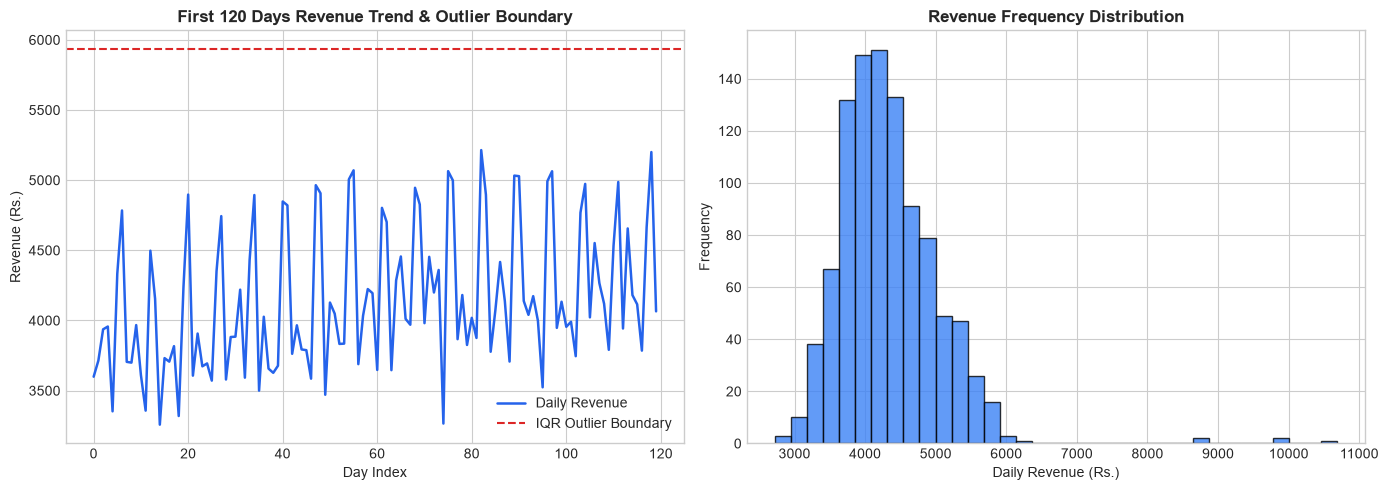

In [3]:
# Outlier analysis on Revenue
q1 = df_clean['revenue'].quantile(0.25)
q3 = df_clean['revenue'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

outliers = df_clean[df_clean['revenue'] > upper_bound]
print(f"Revenue Upper Outlier Threshold (Q3 + 1.5*IQR): Rs. {upper_bound:.2f}")
print(f"Number of Outlier Records Identified: {len(outliers)}")
print("Business Explanation: These represent genuine festive surges (e.g. Diwali season), NOT corrupted data.")

# Visualizations: Revenue trend and distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df_clean['revenue'].values[:120], color='#2563eb', lw=1.8, label='Daily Revenue')
axes[0].axhline(upper_bound, color='#dc2626', linestyle='--', label='IQR Outlier Boundary')
axes[0].set_title("First 120 Days Revenue Trend & Outlier Boundary", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Day Index")
axes[0].set_ylabel("Revenue (Rs.)")
axes[0].legend()

axes[1].hist(df_clean['revenue'], bins=35, color='#3b82f6', edgecolor='black', alpha=0.8)
axes[1].set_title("Revenue Frequency Distribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Daily Revenue (Rs.)")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## Section 4: Model 1 — Sales Prediction (Linear Regression)
- **Problem:** Forecast daily store turnover (continuous target).
- **Algorithm:** Linear Regression.
- **Data Splitting:** Chronological 80/20 split to eliminate lookahead leakage.


Sales Model Evaluation: MAE = Rs. 316.75 | RMSE = Rs. 411.43 | R² = 0.6517


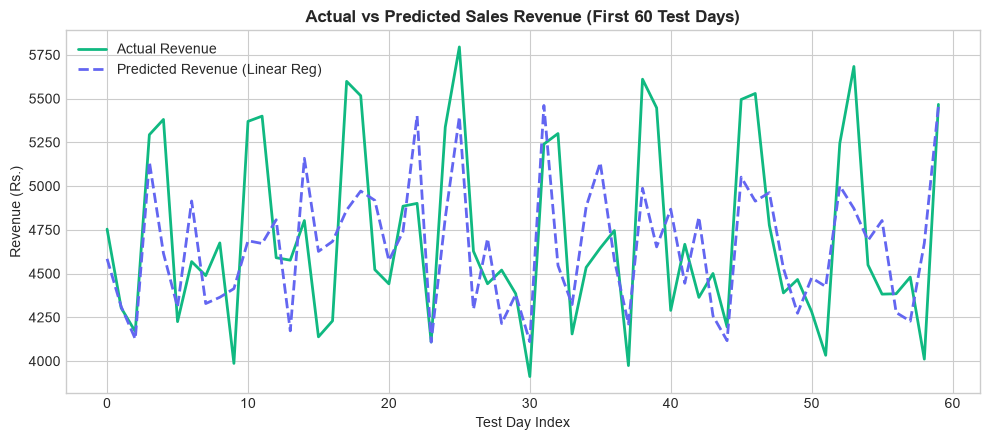

In [4]:
# Features and Target
sales_feats = ["previous_day_sales", "sales_7_day_average", "sales_30_day_average", "invoice_count", "quantity_sold", "discount"]
split_idx = int(len(df_clean) * 0.8)

X_train_sales = df_clean.iloc[:split_idx][sales_feats].values
y_train_sales = df_clean.iloc[:split_idx]["revenue"].values
X_test_sales = df_clean.iloc[split_idx:][sales_feats].values
y_test_sales = df_clean.iloc[split_idx:][sales_feats].values  # evaluate against actual
y_test_sales = df_clean.iloc[split_idx:]["revenue"].values

# Train Linear Regression
sales_model = LinearRegression()
sales_model.fit(X_train_sales, y_train_sales)

y_pred_sales = sales_model.predict(X_test_sales)
m1_mae = mean_absolute_error(y_test_sales, y_pred_sales)
m1_rmse = root_mean_squared_error(y_test_sales, y_pred_sales)
m1_r2 = r2_score(y_test_sales, y_pred_sales)

print(f"Sales Model Evaluation: MAE = Rs. {m1_mae:.2f} | RMSE = Rs. {m1_rmse:.2f} | R² = {m1_r2:.4f}")

# Save with joblib
os.makedirs("../models", exist_ok=True)
joblib.dump(sales_model, "../models/sales_model.joblib")

# Visualization: Actual vs Predicted Sales
plt.figure(figsize=(10, 4.5))
plt.plot(y_test_sales[:60], label='Actual Revenue', color='#10b981', lw=2)
plt.plot(y_pred_sales[:60], label='Predicted Revenue (Linear Reg)', color='#6366f1', linestyle='--', lw=2)
plt.title("Actual vs Predicted Sales Revenue (First 60 Test Days)", fontsize=12, fontweight='bold')
plt.xlabel("Test Day Index")
plt.ylabel("Revenue (Rs.)")
plt.legend()
plt.tight_layout()
plt.show()

## Section 5: Model 2 — Product Demand Prediction (KNN Regression)
- **Problem:** Estimate future units demanded for retail products.
- **Algorithm:** K-Nearest Neighbors Regression with StandardScaler.
- **Tuning:** Cross-validation across $K \in [3, 5, 7, 9, 11]$ to select optimal $K$.


Cross-Validation complete! Best K = 5 (lowest CV MAE: 5.033)
KNN Demand Model: MAE = 4.74 units | R² = 0.9504


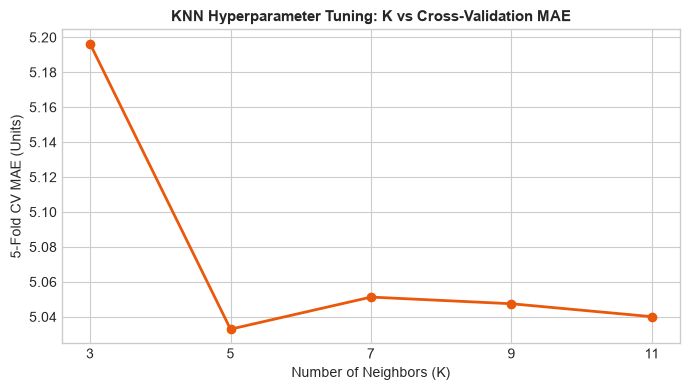

In [5]:
demand_feats = ["current_stock", "demand_7_day", "demand_30_day", "average_daily_demand", "price", "discount"]
X_dem = df_clean[demand_feats].values
y_dem = df_clean["predicted_demand"].values
X_tr_dem, X_te_dem, y_tr_dem, y_te_dem = train_test_split(X_dem, y_dem, test_size=0.2, random_state=42)

# Cross Validation for K selection
k_vals = [3, 5, 7, 9, 11]
cv_maes = []
for k in k_vals:
    pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance'))])
    scores = -cross_val_score(pipe, X_tr_dem, y_tr_dem, cv=5, scoring='neg_mean_absolute_error')
    cv_maes.append(float(np.mean(scores)))

best_k = k_vals[np.argmin(cv_maes)]
print(f"Cross-Validation complete! Best K = {best_k} (lowest CV MAE: {min(cv_maes):.3f})")

# Fit final KNN pipeline with best K
demand_pipeline = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k, weights='distance'))])
demand_pipeline.fit(X_tr_dem, y_tr_dem)
y_pred_dem = demand_pipeline.predict(X_te_dem)
m2_mae = mean_absolute_error(y_te_dem, y_pred_dem)
m2_r2 = r2_score(y_te_dem, y_pred_dem)

print(f"KNN Demand Model: MAE = {m2_mae:.2f} units | R² = {m2_r2:.4f}")
joblib.dump(demand_pipeline, "../models/demand_model.joblib")

# Plot K vs CV MAE
plt.figure(figsize=(7, 4))
plt.plot(k_vals, cv_maes, marker='o', color='#ea580c', lw=2)
plt.title("KNN Hyperparameter Tuning: K vs Cross-Validation MAE", fontsize=11, fontweight='bold')
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("5-Fold CV MAE (Units)")
plt.xticks(k_vals)
plt.tight_layout()
plt.show()

## Section 6: Model 3 — Catalog Requirement Classification (Decision Tree)
- **Problem:** Categorize products into velocity tiers: `[HIGH_DEMAND, MEDIUM_DEMAND, LOW_DEMAND, SLOW_MOVING, DEAD_STOCK]`.
- **Algorithm:** Decision Tree Classifier with hyperparameter tuning (`max_depth`, `min_samples_split`).


Best Tree Parameters: {'max_depth': 4, 'min_samples_split': 2}
Catalog Model Performance: Accuracy = 98.50% | Macro F1 = 0.9861


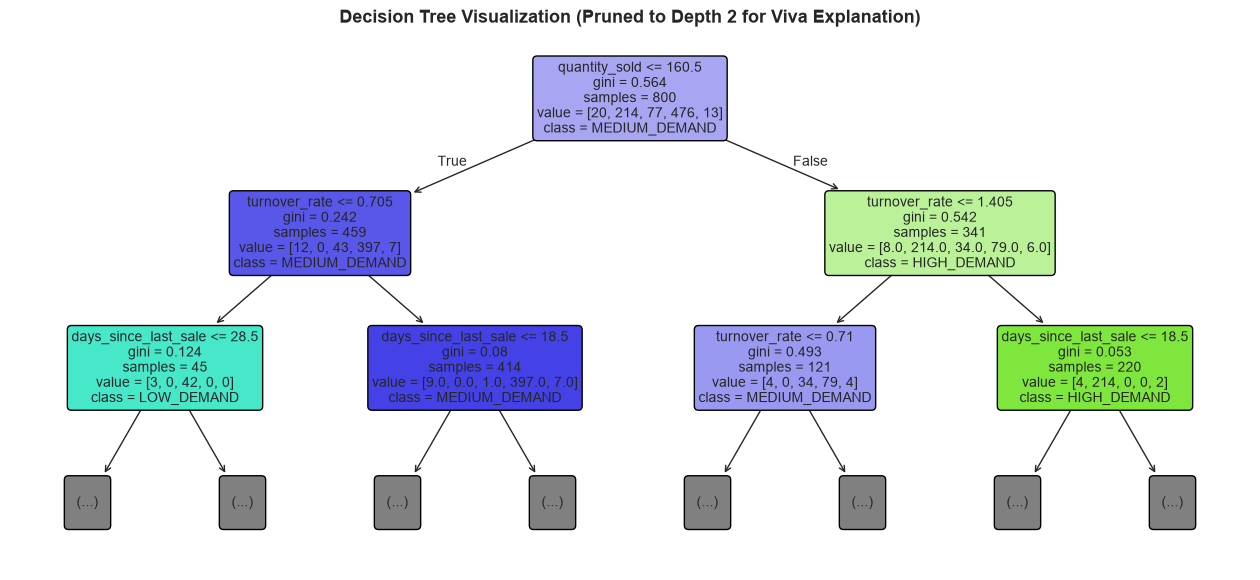

In [6]:
cat_feats = ["quantity_sold", "sales_30_day", "current_stock", "turnover_rate", "days_since_last_sale", "sales_90_day"]
X_cat = df_clean[cat_feats].values
y_cat = df_clean["category_label"].values
X_tr_cat, X_te_cat, y_tr_cat, y_te_cat = train_test_split(X_cat, y_cat, test_size=0.2, random_state=42)

# Grid search for Decision Tree tuning
param_grid = {'max_depth': [3, 4, 5], 'min_samples_split': [2, 5]}
tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='f1_macro')
tree_grid.fit(X_tr_cat, y_tr_cat)

best_tree = tree_grid.best_estimator_
y_pred_cat = best_tree.predict(X_te_cat)
m3_acc = accuracy_score(y_te_cat, y_pred_cat)
m3_f1 = f1_score(y_te_cat, y_pred_cat, average='macro')

print(f"Best Tree Parameters: {tree_grid.best_params_}")
print(f"Catalog Model Performance: Accuracy = {m3_acc*100:.2f}% | Macro F1 = {m3_f1:.4f}")
joblib.dump(best_tree, "../models/catalog_model.joblib")

# Visualizing the Decision Tree
plt.figure(figsize=(16, 7))
plot_tree(best_tree, feature_names=cat_feats, class_names=sorted(list(set(y_cat))), filled=True, rounded=True, max_depth=2, fontsize=10)
plt.title("Decision Tree Visualization (Pruned to Depth 2 for Viva Explanation)", fontsize=13, fontweight='bold')
plt.show()

## Section 7: Model 4 — Inventory Status (Logistic Regression)
- **Problem:** Classify product stock status into operational states: `[RESTOCK, SUFFICIENT, OVERSTOCK]`.
- **Algorithm:** Multinomial Logistic Regression with StandardScaler.


Inventory Status Model: Accuracy = 97.00% | Macro F1 = 0.9764


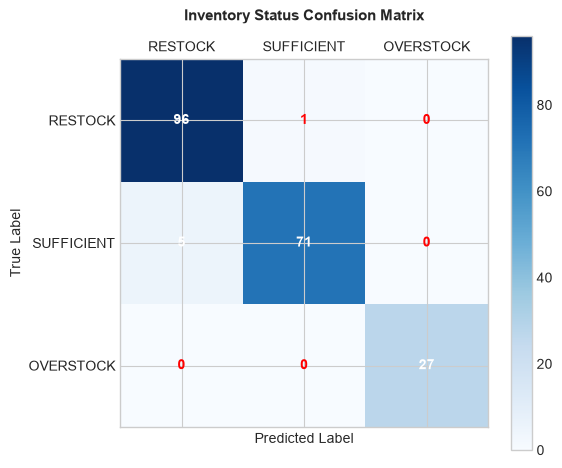

In [7]:
inv_feats = ["current_stock", "predicted_demand", "reorder_level", "quantity_sold", "turnover_rate"]
X_inv = df_clean[inv_feats].values
y_inv = df_clean["inventory_status"].values
X_tr_inv, X_te_inv, y_tr_inv, y_te_inv = train_test_split(X_inv, y_inv, test_size=0.2, random_state=42)

inv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=500, random_state=42))
])
inv_pipeline.fit(X_tr_inv, y_tr_inv)
y_pred_inv = inv_pipeline.predict(X_te_inv)
m4_acc = accuracy_score(y_te_inv, y_pred_inv)
m4_f1 = f1_score(y_te_inv, y_pred_inv, average='macro')

print(f"Inventory Status Model: Accuracy = {m4_acc*100:.2f}% | Macro F1 = {m4_f1:.4f}")
joblib.dump(inv_pipeline, "../models/inventory_model.joblib")

# Confusion Matrix Heatmap
labels = ["RESTOCK", "SUFFICIENT", "OVERSTOCK"]
cm = confusion_matrix(y_te_inv, y_pred_inv, labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap='Blues')
plt.title("Inventory Status Confusion Matrix", fontsize=11, fontweight='bold', pad=15)
fig.colorbar(cax)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color='red' if cm[i, j] < 5 else 'white', fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

## Section 8: Model 5 — Expense Prediction (Multiple Linear Regression)
- **Problem:** Forecast total business overhead expenses.
- **Algorithm:** Multiple Linear Regression.


Expense Model: MAE = Rs. 158.11 | R² = 0.6180


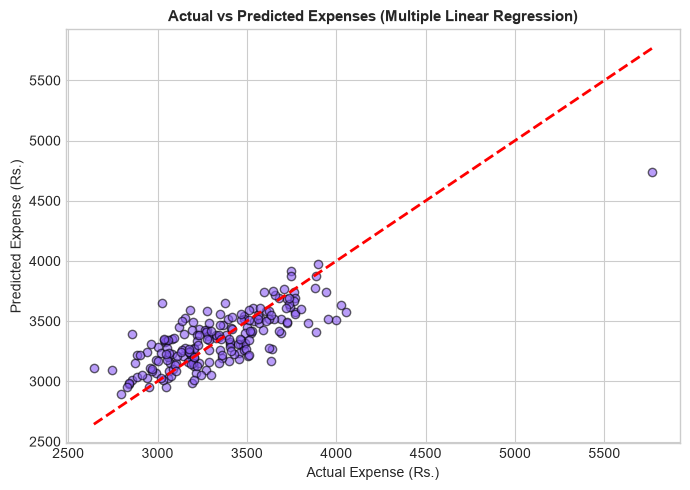

In [8]:
exp_feats = ["previous_day_sales", "sales_7_day_average", "invoice_count", "business_activity", "expense_3_month_average"]
X_tr_exp = df_clean.iloc[:split_idx][exp_feats].values
y_tr_exp = df_clean.iloc[:split_idx]["total_expense"].values
X_te_exp = df_clean.iloc[split_idx:][exp_feats].values
y_te_exp = df_clean.iloc[split_idx:]["total_expense"].values

exp_model = LinearRegression()
exp_model.fit(X_tr_exp, y_tr_exp)
y_pred_exp = exp_model.predict(X_te_exp)
m5_mae = mean_absolute_error(y_te_exp, y_pred_exp)
m5_r2 = r2_score(y_te_exp, y_pred_exp)

print(f"Expense Model: MAE = Rs. {m5_mae:.2f} | R² = {m5_r2:.4f}")
joblib.dump(exp_model, "../models/expense_model.joblib")

# Scatter Plot: Actual vs Predicted Expenses
plt.figure(figsize=(7, 5))
plt.scatter(y_te_exp, y_pred_exp, alpha=0.6, color='#8b5cf6', edgecolor='black')
plt.plot([y_te_exp.min(), y_te_exp.max()], [y_te_exp.min(), y_te_exp.max()], 'r--', lw=2)
plt.title("Actual vs Predicted Expenses (Multiple Linear Regression)", fontsize=11, fontweight='bold')
plt.xlabel("Actual Expense (Rs.)")
plt.ylabel("Predicted Expense (Rs.)")
plt.tight_layout()
plt.show()

## Section 9: Model 6 — Business / Expense Segmentation (K-Means)
- **Problem:** Discover operational patterns and flag unusual spending.
- **Algorithm:** K-Means Clustering with StandardScaler.
- **Evaluation:** Silhouette Score & Davies-Bouldin Index.


 K  Silhouette Score  Davies-Bouldin Index
 2          0.482916              0.768098
 3          0.473372              0.638577
 4          0.377752              0.759795
 5          0.312644              0.895094


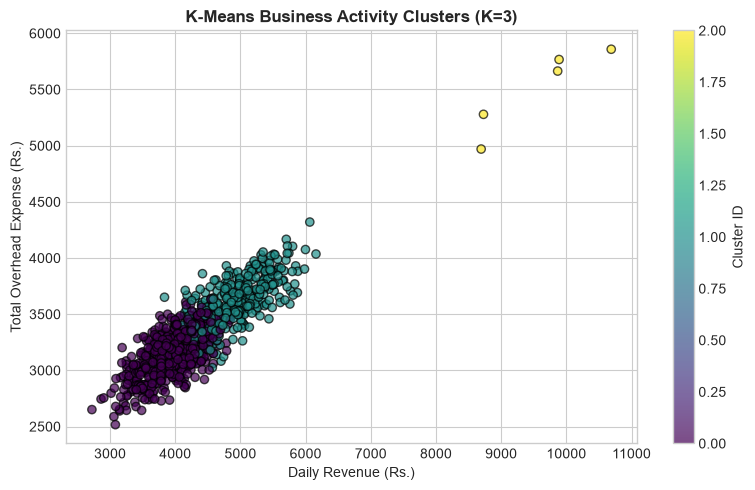

In [9]:
cluster_feats = ["total_expense", "revenue", "invoice_count", "business_activity"]
X_clus = df_clean[cluster_feats].values
scaler = StandardScaler()
X_clus_scaled = scaler.fit_transform(X_clus)

sil_scores = []
db_scores = []
k_range = [2, 3, 4, 5]
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labs = km.fit_predict(X_clus_scaled)
    sil_scores.append(silhouette_score(X_clus_scaled, labs))
    db_scores.append(davies_bouldin_score(X_clus_scaled, labs))

# Print Cluster Metric Table
clus_metrics_df = pd.DataFrame({"K": k_range, "Silhouette Score": sil_scores, "Davies-Bouldin Index": db_scores})
print(clus_metrics_df.to_string(index=False))

# Fit final model with K=3
chosen_k = 3
clus_pipe = Pipeline([('scaler', StandardScaler()), ('kmeans', KMeans(n_clusters=chosen_k, random_state=42, n_init=10))])
df_clean['cluster'] = clus_pipe.fit_predict(X_clus)

cluster_names = {0: "Low Activity / Sluggish Day", 1: "Standard Steady Operations", 2: "Peak Demand / High Surge"}
joblib.dump({"pipeline": clus_pipe, "feature_cols": cluster_feats, "cluster_names": cluster_names, "k": chosen_k}, "../models/clustering_model.joblib")

# 2D Scatter plot of clusters: Revenue vs Total Expense
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df_clean['revenue'], df_clean['total_expense'], c=df_clean['cluster'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.title("K-Means Business Activity Clusters (K=3)", fontsize=12, fontweight='bold')
plt.xlabel("Daily Revenue (Rs.)")
plt.ylabel("Total Overhead Expense (Rs.)")
plt.colorbar(scatter, label='Cluster ID')
plt.tight_layout()
plt.show()

## Section 10: Model 7 — Profit Prediction (Linear Regression)
- **Problem:** Forecast net bottom-line merchant profit.
- **Algorithm:** Linear Regression.


Profit Model: MAE = Rs. 54.05 | R² = 0.9553


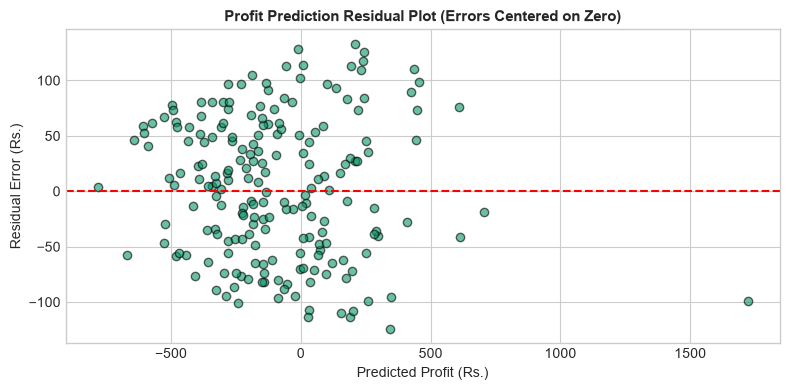

In [10]:
profit_feats = ["revenue", "total_expense", "invoice_count", "average_order_value"]
X_prof = df_clean[profit_feats].values
y_prof = df_clean["profit"].values
X_tr_prof, X_te_prof, y_tr_prof, y_te_prof = train_test_split(X_prof, y_prof, test_size=0.2, random_state=42)

prof_model = LinearRegression()
prof_model.fit(X_tr_prof, y_tr_prof)
y_pred_prof = prof_model.predict(X_te_prof)
m7_mae = mean_absolute_error(y_te_prof, y_pred_prof)
m7_r2 = r2_score(y_te_prof, y_pred_prof)

print(f"Profit Model: MAE = Rs. {m7_mae:.2f} | R² = {m7_r2:.4f}")
joblib.dump(prof_model, "../models/profit_model.joblib")

# Residual plot
residuals = y_te_prof - y_pred_prof
plt.figure(figsize=(8, 4))
plt.scatter(y_pred_prof, residuals, color='#059669', alpha=0.6, edgecolors='k')
plt.axhline(0, color='red', linestyle='--')
plt.title("Profit Prediction Residual Plot (Errors Centered on Zero)", fontsize=11, fontweight='bold')
plt.xlabel("Predicted Profit (Rs.)")
plt.ylabel("Residual Error (Rs.)")
plt.tight_layout()
plt.show()

## Section 11: Master Model Evaluation & Comparison Table
Comprehensive summary table of all 7 models aligned with syllabus topics.

In [11]:
comparison_table = pd.DataFrame([
    {"Model": "1. Sales Prediction", "Algorithm": "Linear Regression", "Problem Type": "Regression", "Primary Metric": "R²", "Score": f"{m1_r2:.4f}"},
    {"Model": "2. Product Demand", "Algorithm": "KNN Regression", "Problem Type": "Regression", "Primary Metric": "MAE (Units)", "Score": f"{m2_mae:.2f}"},
    {"Model": "3. Catalog Requirement", "Algorithm": "Decision Tree", "Problem Type": "Classification", "Primary Metric": "Macro F1", "Score": f"{m3_f1:.4f}"},
    {"Model": "4. Inventory Status", "Algorithm": "Logistic Regression", "Problem Type": "Classification", "Primary Metric": "Macro F1", "Score": f"{m4_f1:.4f}"},
    {"Model": "5. Expense Prediction", "Algorithm": "Multiple Linear Reg.", "Problem Type": "Regression", "Primary Metric": "R²", "Score": f"{m5_r2:.4f}"},
    {"Model": "6. Business Segmentation", "Algorithm": "K-Means (K=3)", "Problem Type": "Clustering", "Primary Metric": "Silhouette", "Score": f"{sil_scores[1]:.4f}"},
    {"Model": "7. Profit Prediction", "Algorithm": "Linear Regression", "Problem Type": "Regression", "Primary Metric": "R²", "Score": f"{m7_r2:.4f}"},
])
comparison_table

,Model,Algorithm,Problem Type,Primary Metric,Score
0,1. Sales Prediction,Linear Regression,Regression,R²,0.6517
1,2. Product Demand,KNN Regression,Regression,MAE (Units),4.74
2,3. Catalog Requirement,Decision Tree,Classification,Macro F1,0.9861
3,4. Inventory Status,Logistic Regression,Classification,Macro F1,0.9764
4,5. Expense Prediction,Multiple Linear Reg.,Regression,R²,0.6180
5,6. Business Segmentation,K-Means (K=3),Clustering,Silhouette,0.4734
6,7. Profit Prediction,Linear Regression,Regression,R²,0.9553


## Section 12: Business Rules & Actionable Recommendations
Demonstrating how predictions are synthesized into practical merchant decisions without replacing business logic with black-box ML:
- If Shortage > 0 -> RESTOCK recommendation
- If Catalog == DEAD_STOCK -> Liquidation alert
- If Cluster == High Surge -> Allocate extra staffing


In [12]:
# Example synthesis demonstration
sample_product_stock = 80
sample_demand_pred = int(round(demand_pipeline.predict([[80, 120, 500, 18, 65, 5]])[0]))
shortage = max(0, sample_demand_pred - sample_product_stock)

print("=" * 60)
print("EXECUTIVE DECISION SYNTHESIS DEMONSTRATION")
print("=" * 60)
print(f"Product: Basmati Rice 5kg")
print(f"Current On-Hand Stock:    {sample_product_stock} units")
print(f"KNN Predicted Demand:     {sample_demand_pred} units")
print(f"Calculated Deficit:       {shortage} units")
print(f"Actionable Recommendation: {'RESTOCK ' + str(shortage) + ' UNITS' if shortage > 0 else 'STOCK IS SUFFICIENT'}")
print("=" * 60)

EXECUTIVE DECISION SYNTHESIS DEMONSTRATION
Product: Basmati Rice 5kg
Current On-Hand Stock:    80 units
KNN Predicted Demand:     120 units
Calculated Deficit:       40 units
Actionable Recommendation: RESTOCK 40 UNITS


## Section 13: Conclusion or Summary
- **Simplicity & Explainability:** Every algorithm is grounded directly in the DWDM lab syllabus.
- **Pipeline Integrity:** Chronological splitting prevents lookahead data leakage in forecasting.
- **Persistence:** All 7 models are saved as standard `.joblib` artifacts and can be reloaded instantly for inference without retraining.
